## 300m indicator - vizualization for bologna

In [3]:
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── Style ────────────────────────────────────────────────────────────────────

TEAL  = "#1D9E75"
BLUE  = "#378ADD"
CORAL = "#F0997B"
LGRAY = "#D3D1C7"
AMBER = "#EF9F27"
TEXT  = "#2C2C2A"
SGRAY = "#888780"

plt.rcParams.update({
    "font.family":        "sans-serif",
    "font.size":          11,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":     0.6,
    "xtick.major.size":   3,
    "ytick.major.size":   3,
    "figure.dpi":         150,
    "savefig.bbox":       "tight",
    "savefig.dpi":        150,
})

In [2]:
import os
os.chdir("/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index")


In [4]:
df = pd.read_csv("data/buildings_300m_indicator.csv")
df["within_300m"] = df["within_300m"].astype(str).str.strip().str.lower() == "true"
df["walk_dist_m"] = pd.to_numeric(df["walk_dist_m"], errors="coerce")
df["park_area_ha"] = pd.to_numeric(df["park_area_ha"], errors="coerce")

TOTAL = len(df)
N_WITHIN = df["within_300m"].sum()
CITY_AVG = N_WITHIN / TOTAL * 100

print(f"Loaded {TOTAL:,} addresses — {N_WITHIN:,} within 300m ({CITY_AVG:.1f}%)")


Loaded 77,630 addresses — 49,134 within 300m (63.3%)


## Results from 300m_computation
- using graphhopper algo, including parks and gardens form DSBN (filter for polygons with more then 6 buildings inside) + osm(this has been just check, since DSBN includes data from osm)

- after applying the algo: 77,630 addresses = 49,134 within 300m (63.3%)


In [6]:
# ── Euclidean distance (haversine, metres) ───────────────────────────────────
# Available for every row that has a matched entrance (within_300m == True).
# For fig3 we need it for all addresses; for rows without an entrance we use
# the nearest-park centroid approach — but here we only have the entrance
# coords, so we restrict the euclid comparison to matched rows only.

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6_371_000
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2) ** 2
    return R * 2 * np.arcsin(np.sqrt(a))

matched = df[df["within_300m"] & df["entrance_lat"].notna()].copy()
matched["euclid_dist_m"] = haversine_m(
    matched["latitude"].values,  matched["longitude"].values,
    matched["entrance_lat"].values, matched["entrance_lon"].values,
)
matched["ratio"] = matched["walk_dist_m"] / matched["euclid_dist_m"]

In [5]:
#check neighborhood data 
neighborhood_na = df['neighbourhood'].isna()
print(neighborhood_na)

0        False
1        False
2        False
3        False
4        False
         ...  
77625    False
77626    False
77627    False
77628    False
77629    False
Name: neighbourhood, Length: 77630, dtype: bool


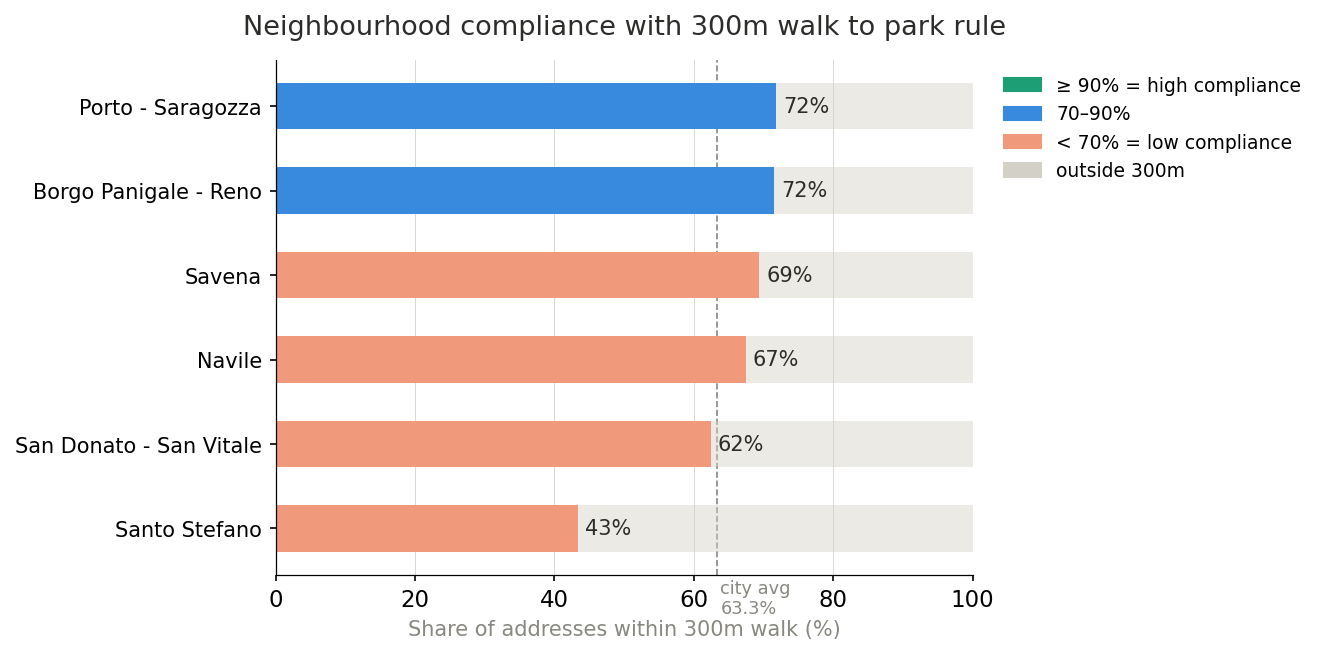

In [14]:

nb = (
    df.groupby("neighbourhood")["within_300m"]
    .agg(total="count", within="sum")
    .assign(pct=lambda x: x["within"] / x["total"] * 100)
    .sort_values("pct", ascending=True)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, max(4.5, len(nb) * 0.55)))

y     = np.arange(len(nb))
bar_h = 0.55
colors = [TEAL if p >= 90 else BLUE if p >= 70 else CORAL for p in nb.pct]

ax.barh(y, nb.pct,           height=bar_h, color=colors, zorder=2)
ax.barh(y, 100 - nb.pct,     height=bar_h, left=nb.pct,
        color=LGRAY, alpha=0.45, zorder=2)

for i, row in nb.iterrows():
    ax.text(row.pct + 1, i, f"{row.pct:.0f}%", va="center", fontsize=10, color=TEXT)
    if row.pct >= 99.5:
        ax.text(row.pct - 2, i, "✓", va="center", ha="right", fontsize=11,
                color="white", fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(nb.neighbourhood, fontsize=10)
ax.set_xlabel("Share of addresses within 300m walk (%)", fontsize=10, color=SGRAY)
ax.set_xlim(0, 115)
ax.set_title("Neighbourhood compliance with 300m walk to park rule", fontsize=13,
             fontweight="500", pad=12, color=TEXT)
ax.axvline(CITY_AVG, color=SGRAY, linewidth=0.8, linestyle="--", zorder=1)
ax.grid(axis="x", linewidth=0.4, color=LGRAY, zorder=0)

legend_els = [
    mpatches.Patch(color=TEAL,  label="≥ 90% = high compliance"),
    mpatches.Patch(color=BLUE,  label="70–90%"),
    mpatches.Patch(color=CORAL, label="< 70% = low compliance"),
    mpatches.Patch(color=LGRAY, label="outside 300m"),
]
ax.set_xlim(0, 100)  # clean 0-100 axis

# move city avg label to bottom of the line instead
ax.text(CITY_AVG + 0.5, -0.6, f"city avg\n{CITY_AVG:.1f}%", 
        fontsize=8.5, color=SGRAY, va="top", ha="left")

# slightly thicker bars
bar_h = 0.65  # was 0.55

# legend outside right, vertically centred
ax.legend(
    handles=legend_els,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=9,
    frameon=False
)

plt.tight_layout()
plt.savefig("fig1_neighbourhood_compliance.png", bbox_inches="tight", dpi=150)
plt.show()



In [ ]:
# Per-neighbourhood breakdown at key thresholds
for threshold in [0, 0.5, 1.0]:
    col = f"compliant_{threshold}ha"
    if threshold == 0:
        df[col] = df["within_300m"]
    else:
        df[col] = df["within_300m"] & (df["park_area_ha"] >= threshold)

nb_detail = df.groupby("neighbourhood").agg(
    total       = ("within_300m", "count"),
    base        = ("compliant_0ha",   "sum"),
    filter_05ha = ("compliant_0.5ha", "sum"),
    filter_1ha  = ("compliant_1.0ha", "sum"),
).assign(
    base_pct    = lambda x: x.base        / x.total * 100,
    pct_05ha    = lambda x: x.filter_05ha / x.total * 100,
    pct_1ha     = lambda x: x.filter_1ha  / x.total * 100,
    drop_05     = lambda x: x.base_pct - x.pct_05ha,
    drop_1      = lambda x: x.base_pct - x.pct_1ha,
).sort_values("base_pct", ascending=False)

print(nb_detail.round(1).to_string())

                         total   base  filter_05ha  filter_1ha  base_pct  pct_05ha  pct_1ha  drop_05  drop_1
neighbourhood                                                                                               
Porto - Saragozza        17302  12430         3975        2487      71.8      23.0     14.4     48.9    57.5
Borgo Panigale - Reno    10669   7632         2204        1315      71.5      20.7     12.3     50.9    59.2
Savena                    7478   5188         1836        1105      69.4      24.6     14.8     44.8    54.6
Navile                   13232   8924         2425        1088      67.4      18.3      8.2     49.1    59.2
San Donato - San Vitale  12629   7880         2634        1328      62.4      20.9     10.5     41.5    51.9
Santo Stefano            16320   7080         1991        1968      43.4      12.2     12.1     31.2    31.3


- Santo Stefano is the outlier at 1ha — it drops only 31% vs 57% for others. Its compliance at 1ha (12.1%) is nearly identical to 0.5ha (12.2%),  meaning its parks are either all large or all tiny, nothing in between.
- Navile has the steepest collapse — 67.4% => 8.2% at 1ha (59% drop). 
- The real city average at 0.5ha is around 20%

In [40]:
!pip install geopandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.2/25.2 MB 4.1 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 3.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 6.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/4 [pyproj]  WARNING: The script pyproj is installed in '/Library/Frameworks/Python.framework/Versions/3.12/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [geopandas]/4 [geopandas]


In [42]:
!pip install osmnx

  Using cached osmnx-2.1.0-py3-none-any.whl.metadata (4.7 kB)
Using cached osmnx-2.1.0-py3-none-any.whl (104 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 11.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [osmnx]32m1/2 [osmnx]


In [49]:
import geopandas as gpd
import osmnx as ox

bologna_nb = ox.geocode_to_gdf("Bologna, Italy")  # city boundary

#bologna - quartieri 
quartieri = ox.features_from_place("Bologna, Italy", tags={"admin_level": "10"})
quartieri = quartieri[quartieri.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
quartieri = quartieri[["name", "geometry"]].reset_index(drop=True)
print(quartieri["name"].tolist())  

['Borgo Panigale-Reno', 'Quartiere Navile', 'San Donato-San Vitale', 'Santo Stefano', 'Porto-Saragozza', 'Savena', 'Ufficio Scuola - Quartiere Navile']


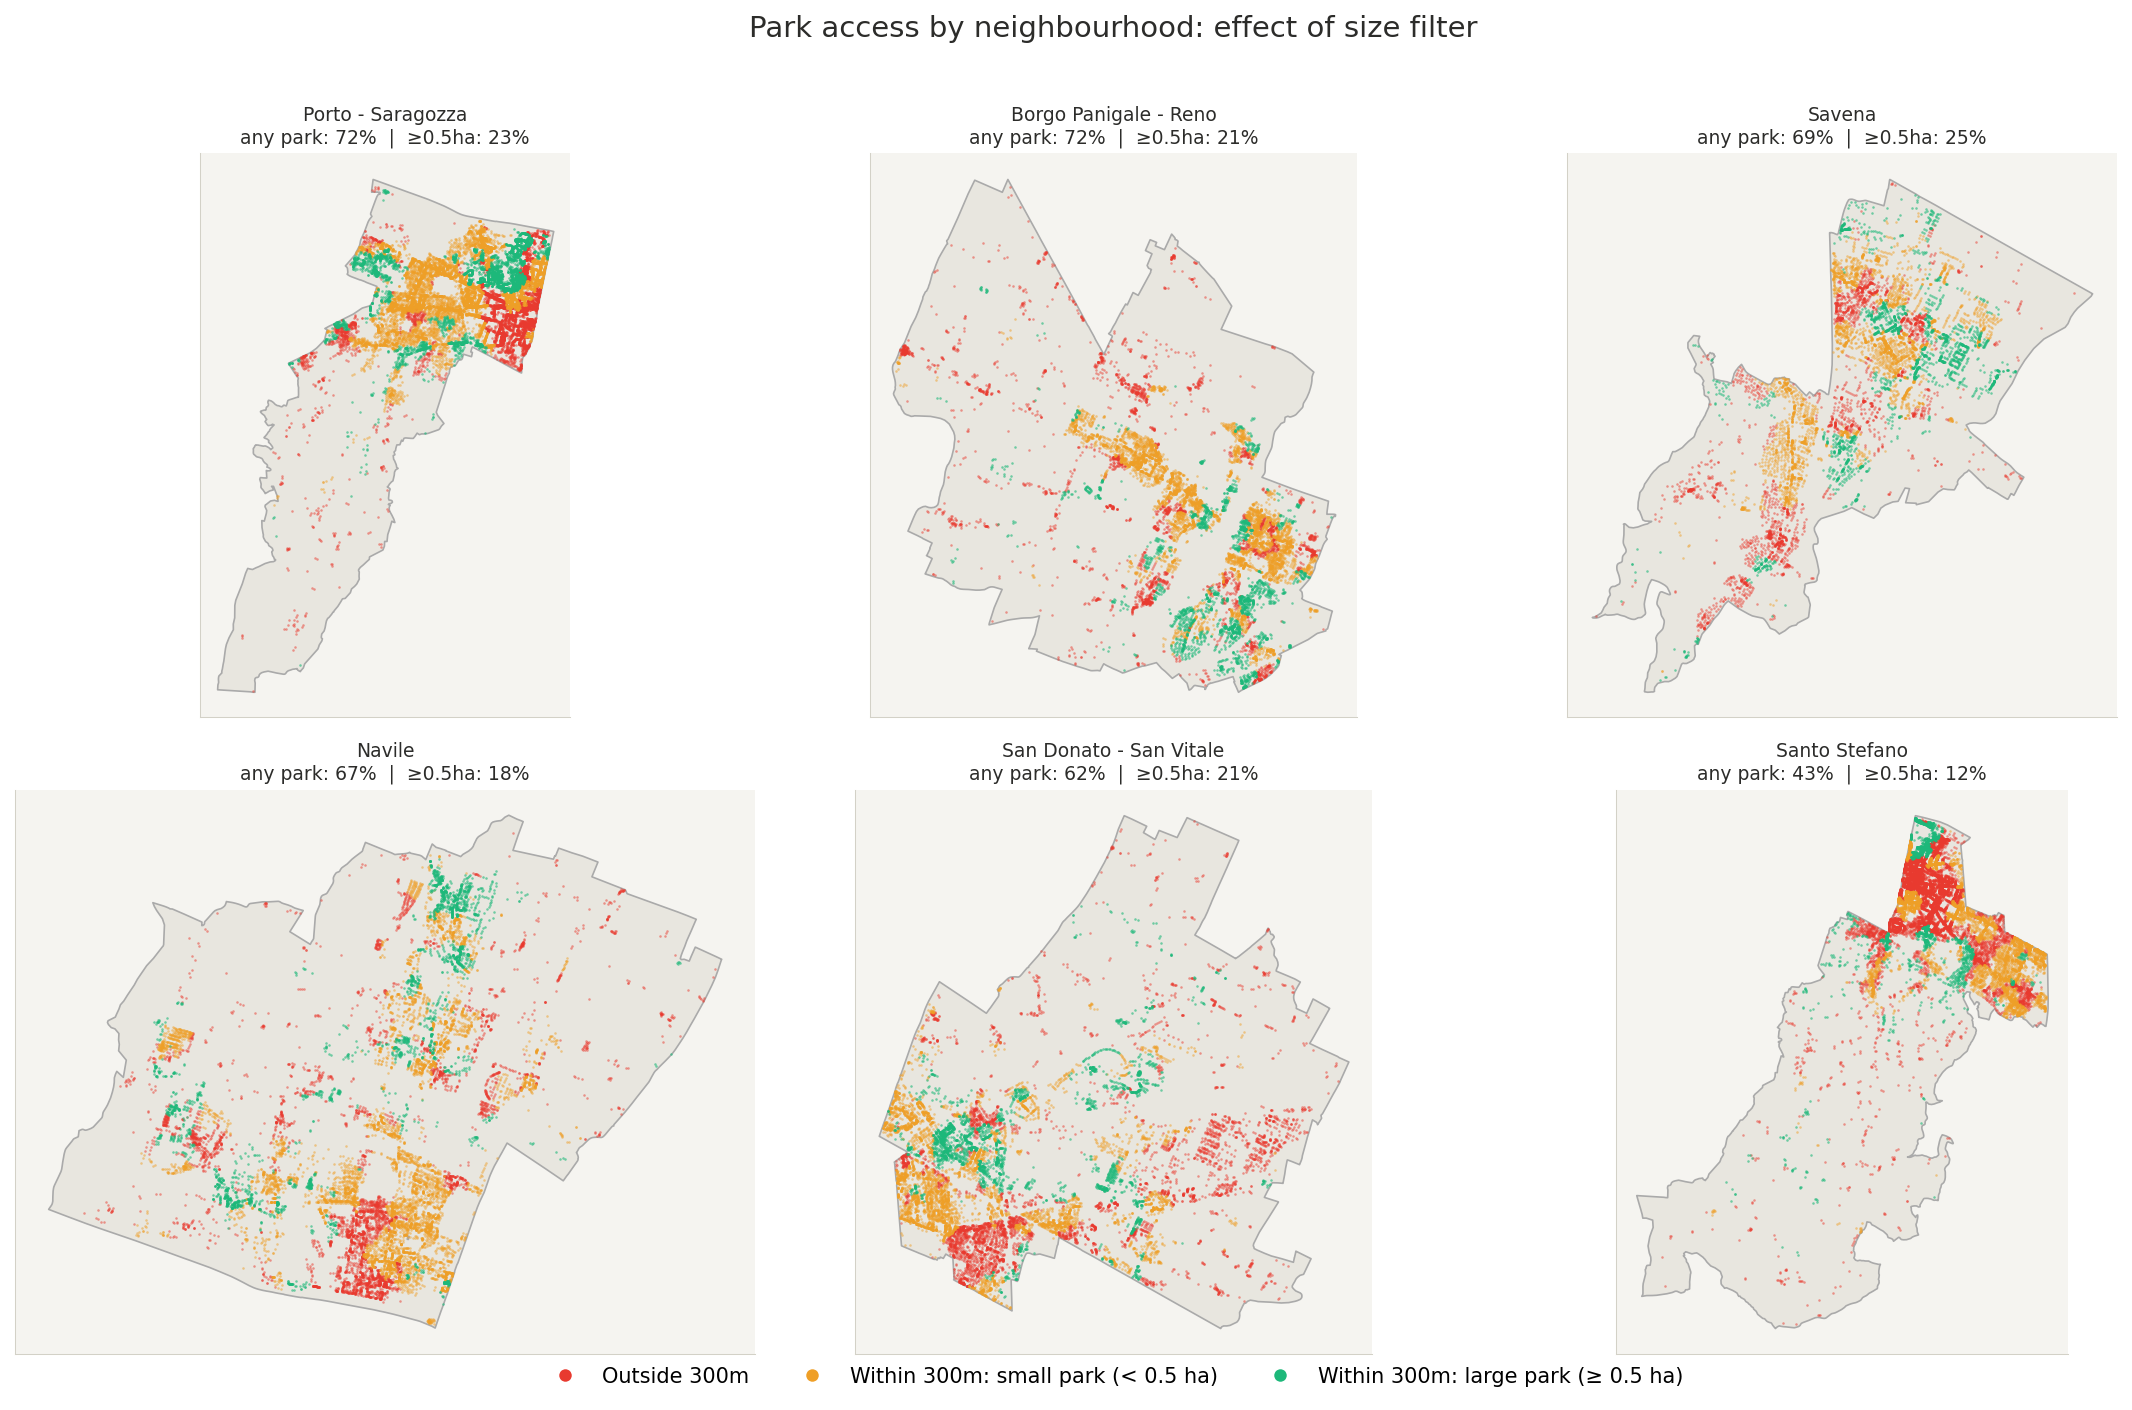

In [51]:
import math 
neighbourhoods = nb_detail.index.tolist()  # already sorted by base_pct
n_cols = 3
n_rows = math.ceil(len(neighbourhoods) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4.5))
axes = axes.flatten()

for i, nb in enumerate(neighbourhoods):
    ax = axes[i]
    nb_df = df[df["neighbourhood"] == nb]
    
    inside  = nb_df[nb_df["within_300m"]]
    outside = nb_df[~nb_df["within_300m"]]
    
    # large parks only (≥ 0.5 ha) — highlight separately
    inside_large = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] >= 0.5)]
    inside_small = nb_df[nb_df["within_300m"] & (nb_df["park_area_ha"] <  0.5)]
    
    nb_geom = quartieri[quartieri["name"].str.contains(nb.split(" - ")[0], case=False)]
    if not nb_geom.empty:
        nb_geom.plot(ax=ax, facecolor="#E8E6DF", edgecolor="#AAAAAA",
                     linewidth=0.8, zorder=1)
    
    ax.set_facecolor("#F5F4F0")
 
    
    ax.scatter(outside["longitude"],     outside["latitude"],
        s=1.5, color="#E83A2F", alpha=0.5, linewidths=0, zorder=2, rasterized=True)
    ax.scatter(inside_small["longitude"], inside_small["latitude"],
        s=1.5, color=AMBER,     alpha=0.5, linewidths=0, zorder=3, rasterized=True)
    ax.scatter(inside_large["longitude"], inside_large["latitude"],
        s=1.5, color="#1DB87A", alpha=0.6, linewidths=0, zorder=4, rasterized=True)

    row = nb_detail.loc[nb]
    ax.set_title(
        f"{nb}\n"
        f"any park: {row.base_pct:.0f}%  |  ≥0.5ha: {row.pct_05ha:.0f}%",
        fontsize=9, color=TEXT, pad=5
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(LGRAY)
        spine.set_linewidth(0.5)

# hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# shared legend
from matplotlib.lines import Line2D
legend_els = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#E83A2F", markersize=7, label="Outside 300m"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=AMBER,     markersize=7, label="Within 300m: small park (< 0.5 ha)"),
    Line2D([0],[0], marker='o', color='w', markerfacecolor="#1DB87A", markersize=7, label="Within 300m: large park (≥ 0.5 ha)"),
]
fig.legend(handles=legend_els, loc="lower center", ncol=3,
    fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Park access by neighbourhood: effect of size filter",
    fontsize=14, fontweight="500", color=TEXT, y=1.01)

plt.tight_layout()
plt.savefig("fig_nb_maps.png", bbox_inches="tight", dpi=180)
plt.show()


## Fig 2 · Park size threshold 
- sicne according to who park should be at least 0,5 ha 

Three address groups at each threshold:
- compliant  — within 300m of a park that meets the size requirement
- lost       — within 300m but their nearest park is smaller than threshold
- never      — never within 300m regardless of size (no park reachable)

"lost" is computed as: was within 300m at baseline, but the matched park is smaller than t ha.  It accumulates as threshold rises.

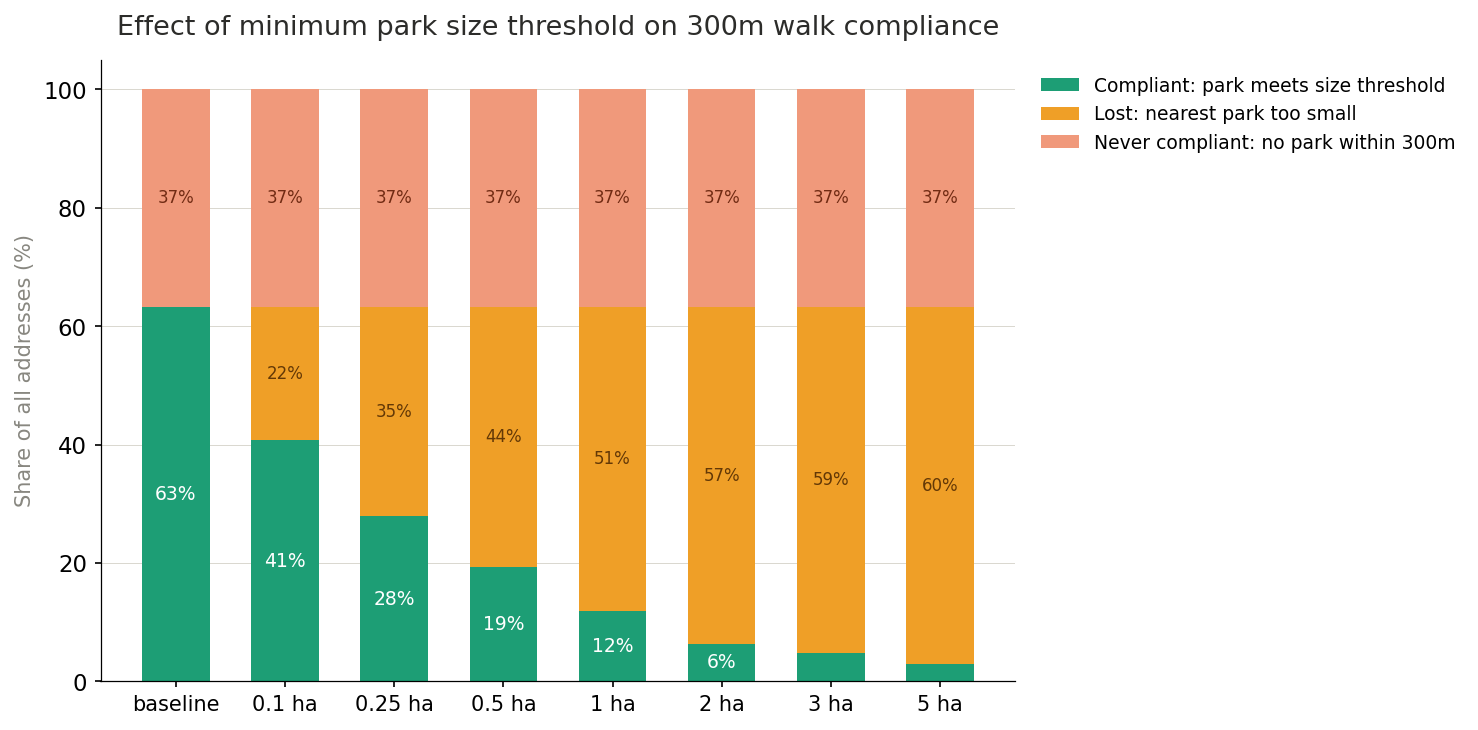

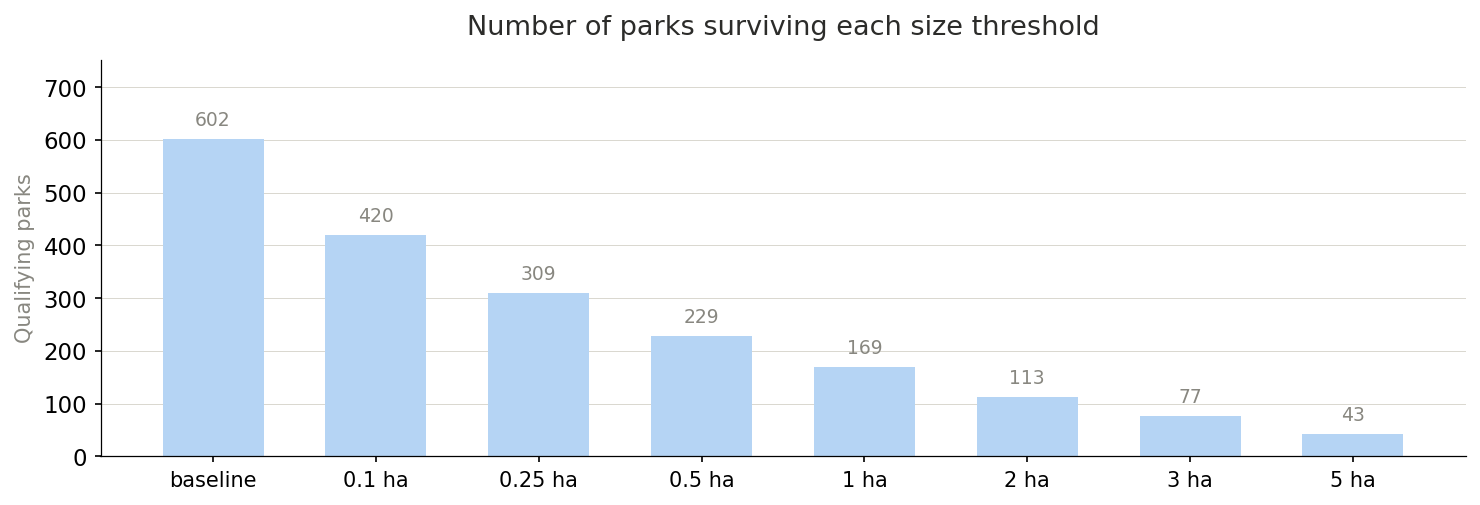

In [20]:
# ── Figure 2a: Stacked compliance bars ──
fig, ax_top = plt.subplots(figsize=(10, 5))

b1 = ax_top.bar(x, size_df.c_pct, width, color=TEAL,  label="Compliant: park meets size threshold", zorder=2)
b2 = ax_top.bar(x, size_df.l_pct, width, bottom=size_df.c_pct, color=AMBER, label="Lost: nearest park too small", zorder=2)
b3 = ax_top.bar(x, size_df.n_pct, width, bottom=size_df.c_pct + size_df.l_pct, color=CORAL, label="Never compliant: no park within 300m", zorder=2)

for i, row in size_df.iterrows():
    if row.c_pct > 5:
        ax_top.text(i, row.c_pct / 2, f"{row.c_pct:.0f}%",
            ha="center", va="center", fontsize=9, color="white", fontweight="500")
    if row.l_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct / 2, f"{row.l_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#633806")
    if row.n_pct > 3:
        ax_top.text(i, row.c_pct + row.l_pct + row.n_pct / 2, f"{row.n_pct:.0f}%",
            ha="center", va="center", fontsize=8, color="#712B13")

ax_top.set_xticks(x)
ax_top.set_xticklabels(xlabels, fontsize=10)
ax_top.set_ylabel("Share of all addresses (%)", fontsize=10, color=SGRAY)
ax_top.set_ylim(0, 105)
ax_top.set_title("Effect of minimum park size threshold on 300m walk compliance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax_top.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)
ax_top.legend(fontsize=9, frameon=False, loc="upper left",
    bbox_to_anchor=(1.01, 1.0))

plt.tight_layout()
plt.savefig("fig2a_compliance_by_size.png", bbox_inches="tight", dpi=150)
plt.show()

# ── Figure 2b: Qualifying parks ──
fig, ax_bot = plt.subplots(figsize=(10, 3.5))

ax_bot.bar(x, size_df.parks, width, color="#B5D4F4", zorder=2)
for i, row in size_df.iterrows():
    ax_bot.text(i, row.parks + size_df.parks.max() * 0.03,
        str(int(row.parks)), ha="center", va="bottom", fontsize=9, color=SGRAY)

ax_bot.set_xticks(x)
ax_bot.set_xticklabels(xlabels, fontsize=10)
ax_bot.set_ylabel("Qualifying parks", fontsize=10, color=SGRAY)
ax_bot.set_title("Number of parks surviving each size threshold",
    fontsize=13, fontweight="500", color=TEXT, pad=12)
ax_bot.set_ylim(0, size_df.parks.max() * 1.25)
ax_bot.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

plt.tight_layout()
plt.savefig("fig2b_parks_by_size.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 3 - Euclidean vs. walk compliance by threshold 
- Note: Euclidean is computed only for matched rows (entrance coords available).
- For unmatched rows, walk_dist_m is NaN → treated as non-compliant at all thresholds, which is correct.

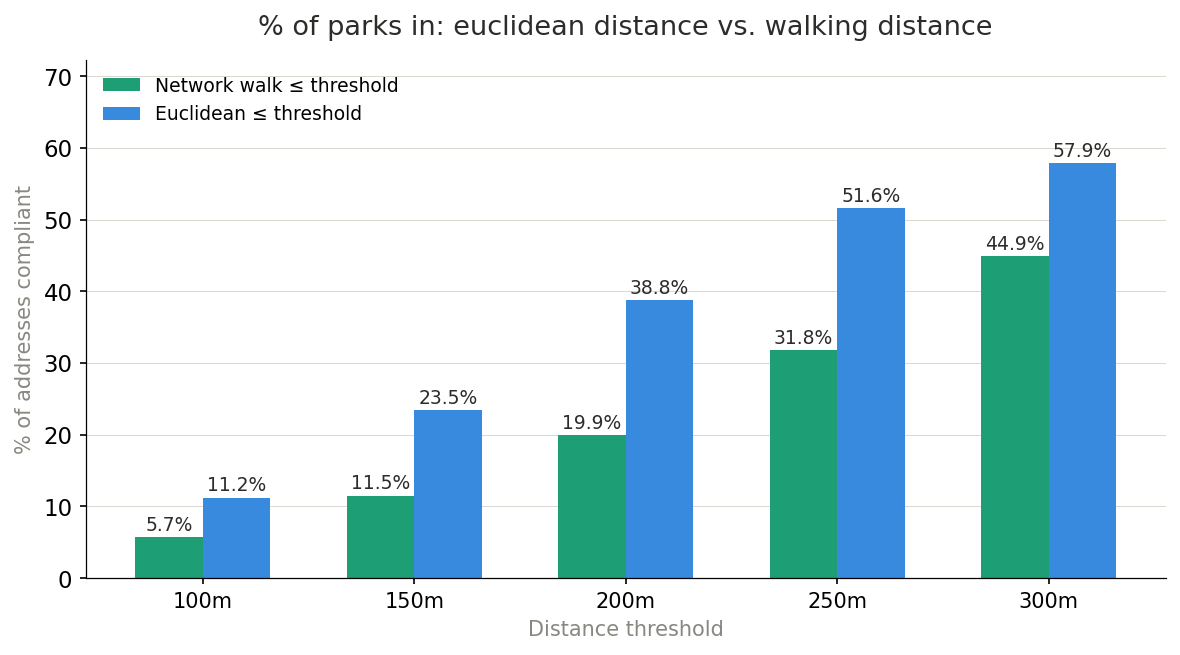

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Grouped bars, no secondary axis
b1 = ax.bar(x - w/2, walk_pct_real,   width=w, color=TEAL, label="Network walk ≤ threshold",  zorder=2, linewidth=0)
b2 = ax.bar(x + w/2, euclid_pct_real, width=w, color=BLUE, label="Euclidean ≤ threshold", zorder=2, linewidth=0)

# Value labels above bars
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.1f}%", ha="center", va="bottom", fontsize=9, color=TEXT)



ax.set_xticks(x)
ax.set_xticklabels([f"{t}m" for t in dist_thresholds], fontsize=10)
ax.set_ylabel("% of addresses compliant", fontsize=10, color=SGRAY)
ax.set_xlabel("Distance threshold", fontsize=10, color=SGRAY)
ax.set_title("% of parks in: euclidean distance vs. walking distance",
    fontsize=13, fontweight="500", pad=12, color=TEXT)
ax.set_ylim(0, max(euclid_pct_real) * 1.25)
ax.grid(axis="y", linewidth=0.4, color=LGRAY, zorder=0)

# clean single legend
ax.legend(handles=[b1, b2], fontsize=9, frameon=False,
    loc="upper left")

plt.tight_layout()
plt.savefig("fig3_euclid_vs_walk.png", bbox_inches="tight", dpi=150)
plt.show()

## Fig 4  - Access gap map = address scatter coloured by 300m compliance

- Each dot = one civic address, plotted at its lon/lat.
- Teal  = within 300m walk of a park
- Coral = outside 300m (the access gap)
- Outside dots are drawn first so inside dots render on top where they overlap.

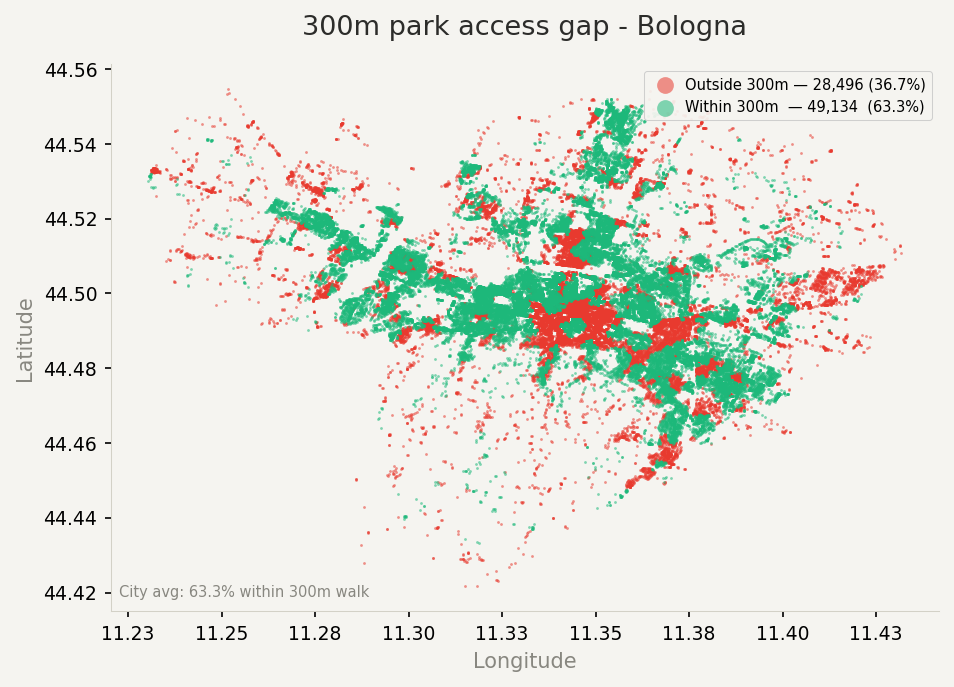

In [34]:
# Brighter colours for dot map
DOT_OUT = "#E83A2F"   # vivid red for outside (the problem)
DOT_IN  = "#1DB87A"   # vivid green for inside (the good)

inside  = df[df["within_300m"]]
outside = df[~df["within_300m"]]

lon_range = df["longitude"].max() - df["longitude"].min()
lat_range = df["latitude"].max()  - df["latitude"].min()
lat_mid   = df["latitude"].mean()
aspect    = lon_range / (lat_range * np.cos(np.radians(lat_mid)))
fig_w, fig_h = 10, 10 / aspect

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor("#F5F4F0")
ax.set_facecolor("#F5F4F0")

# Draw outside first (red), inside on top (green)
ax.scatter(outside["longitude"], outside["latitude"],
    s=1.8, color=DOT_OUT, alpha=0.55, linewidths=0,
    label=f"Outside 300m — {len(outside):,} ({len(outside)/TOTAL*100:.1f}%)",
    rasterized=True, zorder=2)
ax.scatter(inside["longitude"], inside["latitude"],
    s=1.8, color=DOT_IN,  alpha=0.55, linewidths=0,
    label=f"Within 300m  — {len(inside):,}  ({len(inside)/TOTAL*100:.1f}%)",
    rasterized=True, zorder=3)

ax.set_aspect("equal")
ax.set_xlabel("Longitude", fontsize=10, color=SGRAY)
ax.set_ylabel("Latitude",  fontsize=10, color=SGRAY)
ax.set_title("300m park access gap - Bologna",
    fontsize=13, fontweight="500", pad=14, color=TEXT)
ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
ax.tick_params(labelsize=9)
for spine in ax.spines.values():
    spine.set_edgecolor(LGRAY)
    spine.set_linewidth(0.5)

# Legend upper right, slightly inset
legend = ax.legend(
    fontsize=7, frameon=True, framealpha=0.92, loc="upper right",
    markerscale=6, handletextpad=0.4,
)
legend.get_frame().set_linewidth(0.5)
legend.get_frame().set_facecolor("#F5F4F0")

ax.text(0.01, 0.02, f"City avg: {CITY_AVG:.1f}% within 300m walk",
    transform=ax.transAxes, fontsize=7, color=SGRAY, ha="left", va="bottom")

plt.tight_layout()
plt.savefig("fig4_access_gap_map.png", dpi=200, bbox_inches="tight")
plt.show()